In [ ]:
import json
import os
import sys
from pathlib import Path

if "google.colab" in sys.modules and not Path("src").exists():
    print("Запуск у Google Colab — переконайтесь, що папка 'src/' завантажена у робочу директорію.")

import src
import keras
import numpy as np
import pandas as pd
import tensorflow as tf

from src.config import SEED, ensure_directories, set_global_seed

ensure_directories()
set_global_seed(SEED)
accel_info = f"TF devices: {tf.config.list_physical_devices()}"
if keras.backend.backend() == "torch":
    import torch
    mps_ok = torch.backends.mps.is_available()
    accel_info = f"Apple Metal GPU (MPS): {'ACTIVE' if mps_ok else 'CPU'} (torch {torch.__version__})"
print(f"Keras: {keras.__version__} (backend={keras.backend.backend()}) | TensorFlow: {tf.__version__}")
print(f"Апаратне прискорення: {accel_info}")


Keras: 3.15.1 (backend=torch) | TensorFlow: 2.21.0
Апаратне прискорення: Apple Metal GPU (MPS): ACTIVE (torch 2.15.0)


[trainer] Loaded Stage-1 bottleneck features for 'mobilenet_v2' (dim=1280, train=19997).
[trainer] Caching frozen prefix 'mobilenet_v2:block_15_add' shape=(160, 7, 7) (2000 tr / 500 val / 2502 test, temp disk=0.07 GB) ...
[trainer] mobilenet_v2_tune_blocks_1 | Best FT Ep 1/8 | Val Loss: 0.0332 | Test Acc: 98.84% (29 errs) | Time: 18.8s
[trainer] Caching frozen prefix 'mobilenet_v2:block_14_add' shape=(160, 7, 7) (2000 tr / 500 val / 2502 test, temp disk=0.07 GB) ...
[trainer] mobilenet_v2_tune_blocks_2 | Best FT Ep 2/8 | Val Loss: 0.0330 | Test Acc: 98.96% (26 errs) | Time: 26.6s
[trainer] Caching frozen prefix 'mobilenet_v2:block_12_add' shape=(96, 14, 14) (2000 tr / 500 val / 2502 test, temp disk=0.18 GB) ...
[trainer] mobilenet_v2_tune_blocks_3 | Best FT Ep 2/8 | Val Loss: 0.0382 | Test Acc: 99.00% (25 errs) | Time: 47.7s


Prefix [mobilenet_v2:test]: 100%|##########| 79/79 [00:31<00:00,  2.52it/s]


,Config,Unfreeze Scope,Trainable Params,Best Val Loss,Overfit Gap (%),Test Accuracy (%),Test Loss,ROC-AUC
0,1 блок(и),1 блок: block_16 + Conv_1 1280ch (BatchNorm за...,1207233,0.03319,0.65,98.84,0.0322,0.99886
1,2 блок(и),2 блоки: block_15 + block_16 + Conv_1 (BatchNo...,1523073,0.03302,0.45,98.96,0.0316,0.99894
2,3 блок(и),4 блоки: block_13..block_16 + Conv_1 (BatchNor...,1991553,0.03819,1.35,99.00,0.0339,0.99879


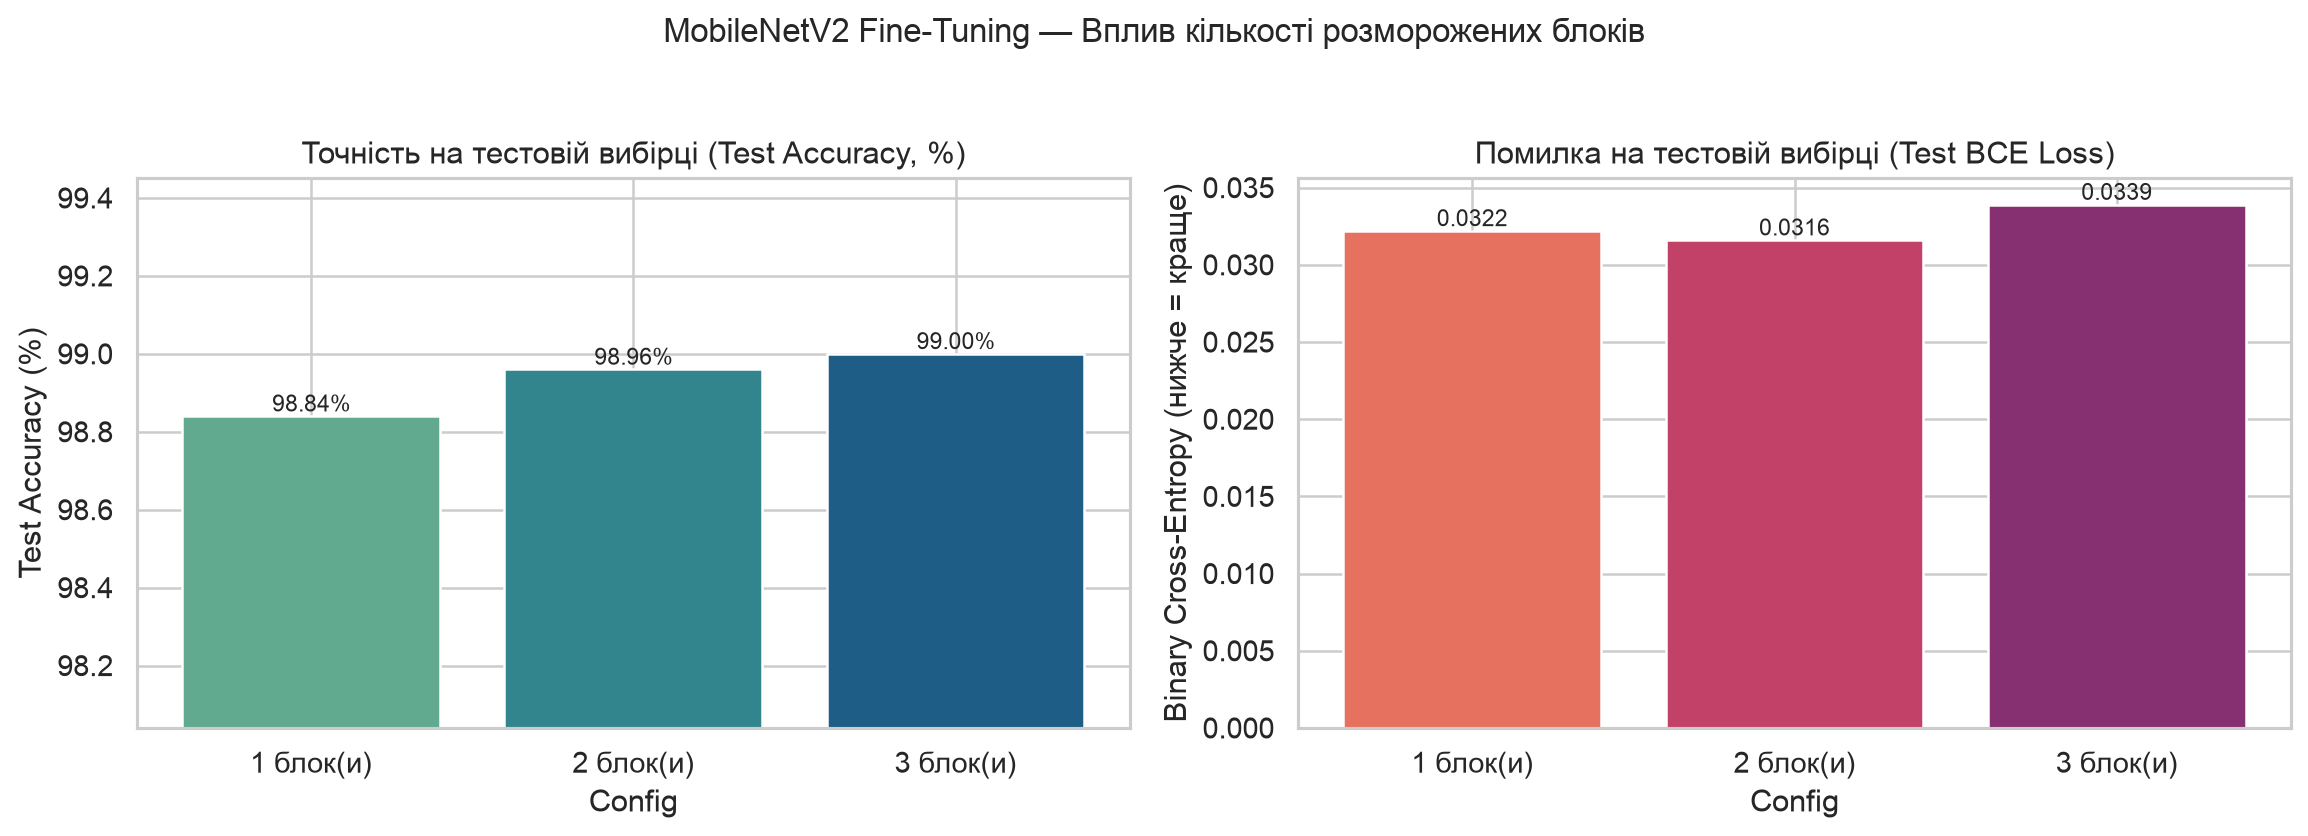

In [ ]:
from src.config import MODELS_DIR, RESULTS_DIR, cleanup_temp_prefix_cache
from src.trainer import (
    extract_or_load_bottleneck_features,
    finalize_and_save_finetuned_model,
    predict_external_images,
    prepare_prefix_cache,
    run_finetuning_experiment,
)
from src.visualization import (
    plot_confusion_matrix,
    plot_external_predictions_grid,
    plot_hyperparameter_bars,
    plot_multi_curves_comparison,
    plot_two_stage_curves,
)

bottleneck_data, _ = extract_or_load_bottleneck_features("mobilenet_v2")

block_rows = []
block_records = []
for n_blk in (1, 2, 3):
    pc_sub = prepare_prefix_cache("mobilenet_v2", unfreeze_blocks=n_blk, train_samples=2000, val_samples=500)
    _, rec = run_finetuning_experiment(
        model_key="mobilenet_v2",
        bottleneck_features=bottleneck_data,
        prefix_cache=pc_sub,
        unfreeze_blocks=n_blk,
        dense_units=256,
        dropout_rate=0.5,
        optimizer_name="adam",
        learning_rate=1e-5,
        batch_size=50,
        warmup_epochs=10,
        finetune_epochs=8,
        experiment_name=f"mobilenet_v2_tune_blocks_{n_blk}",
    )
    block_records.append(rec)
    tm = rec["test_metrics"]
    block_rows.append({
        "Config": f"{n_blk} блок(и)",
        "Unfreeze Scope": rec["unfreeze_description"],
        "Trainable Params": rec["trainable_params"],
        "Best Val Loss": rec["best_val_loss"],
        "Overfit Gap (%)": round(rec["overfitting_acc_gap"] * 100, 2),
        "Test Accuracy (%)": round(tm["accuracy"] * 100, 2),
        "Test Loss": round(tm["loss"], 4),
        "ROC-AUC": round(tm["roc_auc"], 5),
    })

df_blocks = pd.DataFrame(block_rows)
display(df_blocks)
plot_hyperparameter_bars(
    df_blocks,
    x_col="Config",
    title="MobileNetV2 Fine-Tuning — Вплив кількості розморожених блоків",
    save_name="04_mobilenet_v2_blocks_comparison.png",
)


[trainer] Caching frozen prefix 'mobilenet_v2:block_14_add' shape=(160, 7, 7) (2000 tr / 500 val / 2502 test, temp disk=0.07 GB) ...
[trainer] mobilenet_v2_tune_adam_lr_1e-4 | Best FT Ep 4/8 | Val Loss: 0.0487 | Test Acc: 99.16% (21 errs) | Time: 26.3s
[trainer] mobilenet_v2_tune_adam_lr_1e-5 | Best FT Ep 2/8 | Val Loss: 0.0330 | Test Acc: 98.96% (26 errs) | Time: 26.3s
[trainer] mobilenet_v2_tune_adam_lr_1e-6 | Best FT Ep 2/8 | Val Loss: 0.0350 | Test Acc: 98.88% (28 errs) | Time: 26.4s
[trainer] mobilenet_v2_tune_rmsprop_lr_1e-5 | Best FT Ep 1/8 | Val Loss: 0.0324 | Test Acc: 98.84% (29 errs) | Time: 26.0s


Prefix [mobilenet_v2:test]: 100%|##########| 79/79 [00:32<00:00,  2.44it/s]


,Setting,Optimizer,Learning Rate,Best Epoch,Best Val Loss,Overfit Gap (%),Test Accuracy (%),Test Loss,ROC-AUC
0,Adam lr=1e-4,ADAM,0.000100,4,0.04866,1.20,99.16,0.0319,0.99908
1,Adam lr=1e-5,ADAM,0.000010,2,0.03302,0.45,98.96,0.0316,0.99894
2,Adam lr=1e-6,ADAM,0.000001,2,0.03495,0.30,98.88,0.0334,0.99882
3,RMSprop lr=1e-5,RMSPROP,0.000010,1,0.03244,0.45,98.84,0.0320,0.99901


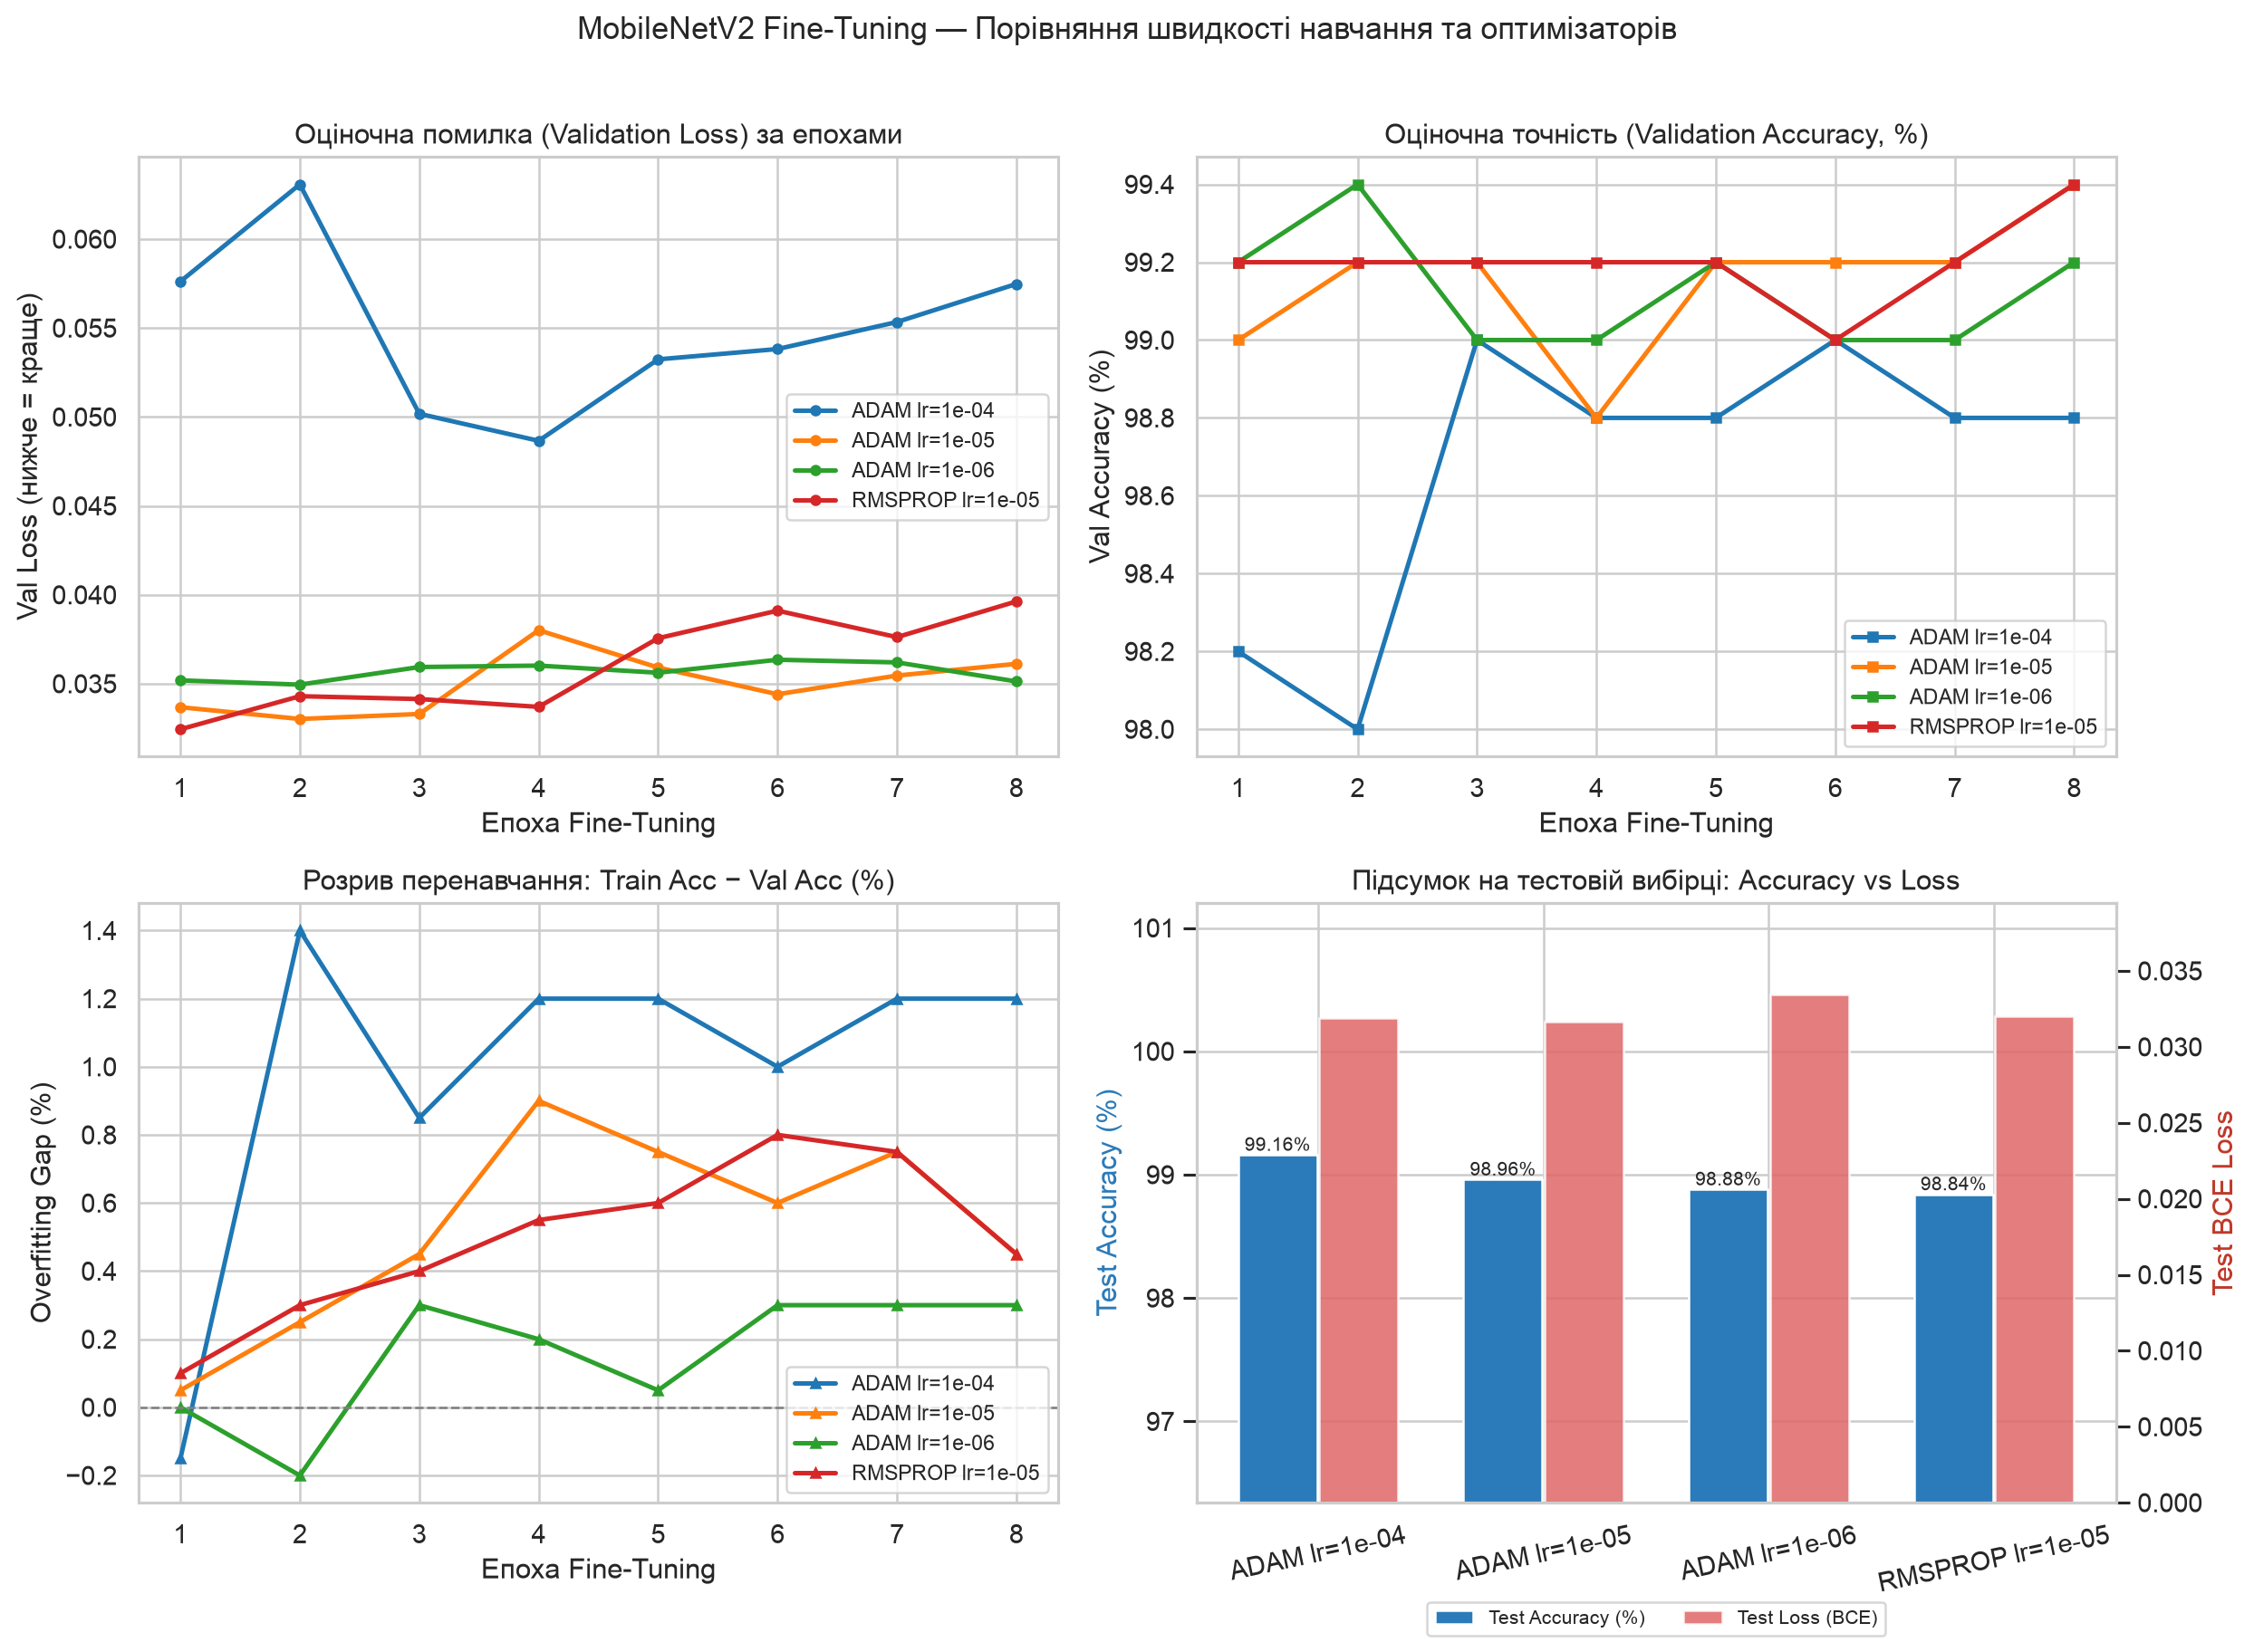

In [3]:
pc_tune = prepare_prefix_cache("mobilenet_v2", unfreeze_blocks=2, train_samples=2000, val_samples=500)
lr_opt_configs = [
    ("Adam lr=1e-4", "adam", 1e-4),
    ("Adam lr=1e-5", "adam", 1e-5),
    ("Adam lr=1e-6", "adam", 1e-6),
    ("RMSprop lr=1e-5", "rmsprop", 1e-5),
]

lr_records = []
lr_rows = []
for label, opt_name, lr_val in lr_opt_configs:
    tag_clean = label.lower().replace(" ", "_").replace("=", "_")
    _, rec = run_finetuning_experiment(
        model_key="mobilenet_v2",
        bottleneck_features=bottleneck_data,
        prefix_cache=pc_tune,
        unfreeze_blocks=2,
        dense_units=256,
        dropout_rate=0.5,
        optimizer_name=opt_name,
        learning_rate=lr_val,
        batch_size=50,
        warmup_epochs=10,
        finetune_epochs=8,
        experiment_name=f"mobilenet_v2_tune_{tag_clean}",
    )
    lr_records.append(rec)
    tm = rec["test_metrics"]
    lr_rows.append({
        "Setting": label,
        "Optimizer": opt_name.upper(),
        "Learning Rate": lr_val,
        "Best Epoch": rec["best_epoch"],
        "Best Val Loss": rec["best_val_loss"],
        "Overfit Gap (%)": round(rec["overfitting_acc_gap"] * 100, 2),
        "Test Accuracy (%)": round(tm["accuracy"] * 100, 2),
        "Test Loss": round(tm["loss"], 4),
        "ROC-AUC": round(tm["roc_auc"], 5),
    })

cleanup_temp_prefix_cache()
df_lr = pd.DataFrame(lr_rows)
display(df_lr)
df_lr.to_csv(RESULTS_DIR / "mobilenet_v2_hyperparameter_studies.csv", index=False)

plot_multi_curves_comparison(
    lr_records,
    label_fn=lambda r: f"{r['optimizer'].upper()} {r['learning_rate']:.0e}",
    suptitle="MobileNetV2 Fine-Tuning — Підбір швидкості навчання та оптимізатора",
    save_name="04_mobilenet_v2_lr_opt_comparison.png",
)


Оптимальний режим донавчання MobileNetV2 за мінімумом Val Loss: optimizer=rmsprop, lr=1e-05, blocks=2
[trainer] Caching frozen prefix 'mobilenet_v2:block_14_add' shape=(160, 7, 7) (19997 tr / 2498 val / 2502 test, temp disk=0.37 GB) ...
[trainer] mobilenet_v2_champion_finetuned | Best FT Ep 1/8 | Val Loss: 0.0267 | Test Acc: 99.12% (22 errs) | Time: 249.9s
Found 19997 files belonging to 2 classes.
Found 2498 files belonging to 2 classes.
Found 2502 files belonging to 2 classes.
[trainer] Verified End-to-End MobileNetV2 on raw test JPEGs (max prob diff vs FP16 prefix split = 0.00002).
[trainer] Saved mobilenet_v2_finetuned.keras (10.43 MB) | Test Acc: 99.12% (22 errs / 2502) | Loss: 0.0251 | ROC-AUC: 0.99918


Prefix [mobilenet_v2:test]: 100%|##########| 79/79 [00:32<00:00,  2.44it/s]


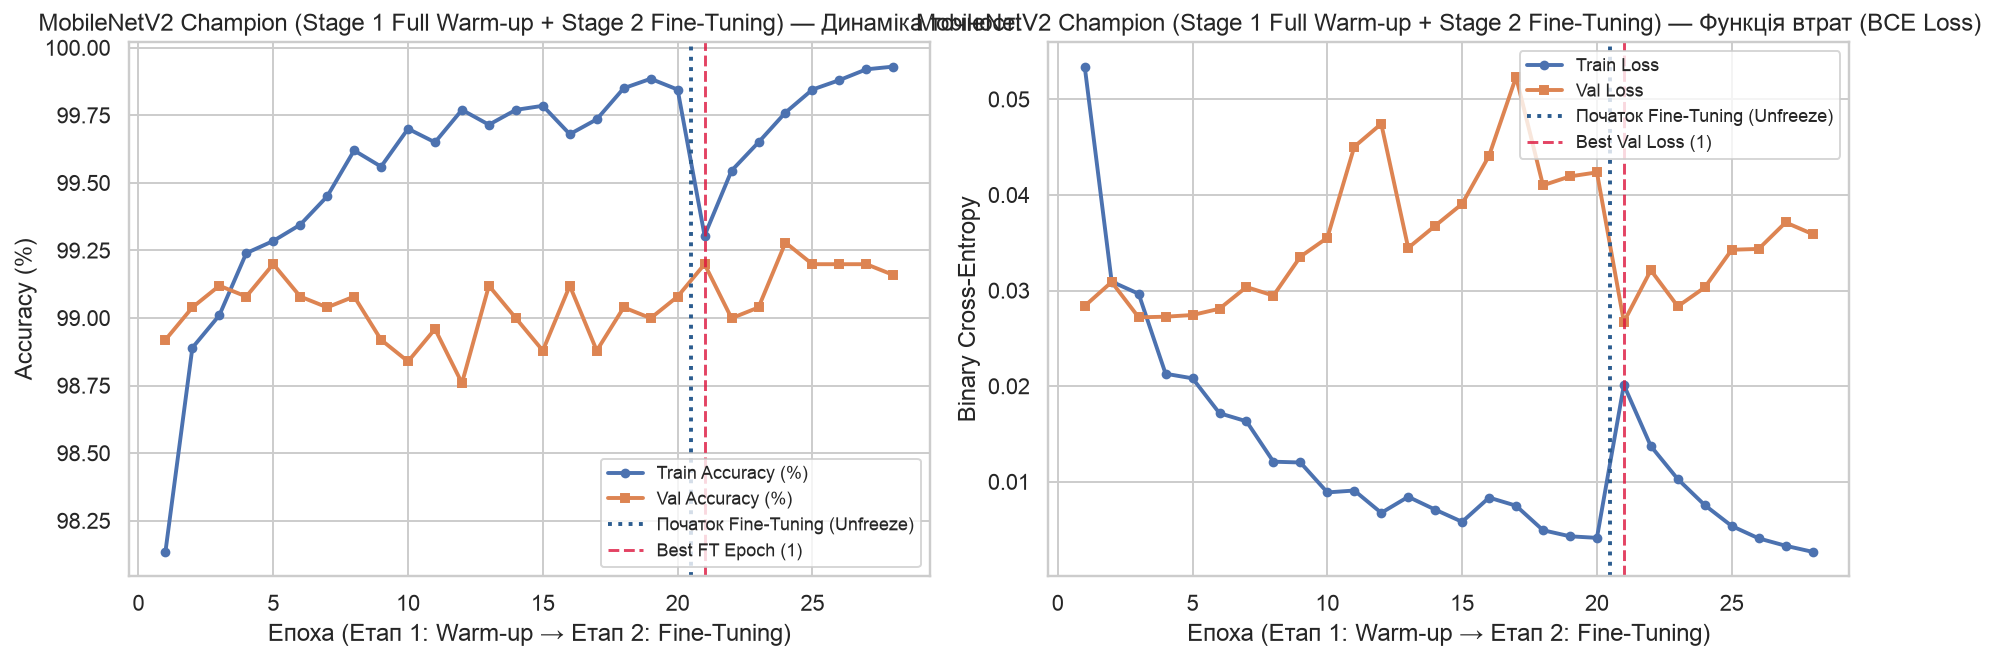

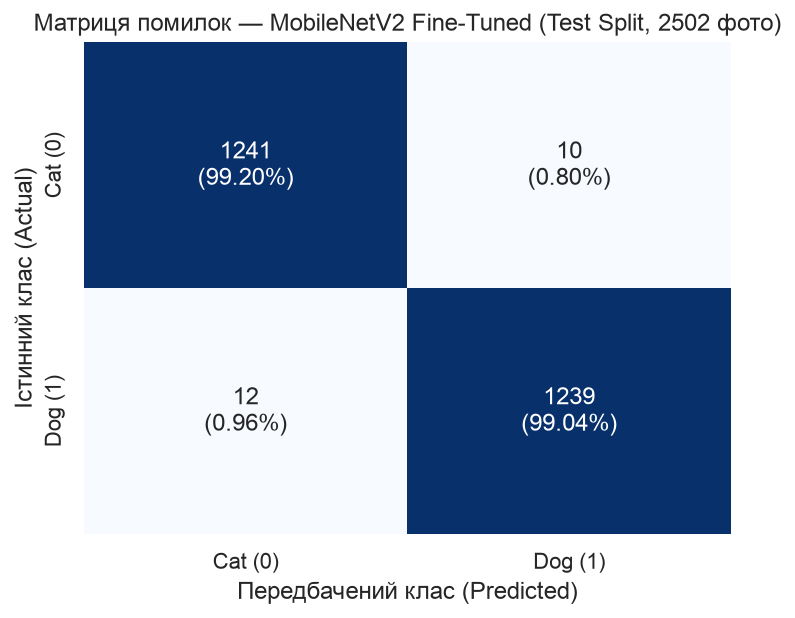

,filename,rel_path,true_class,pred_class,dog_probability,confidence,bce_loss,correct
0,ext_cat_01_tabby.jpg,cats/ext_cat_01_tabby.jpg,cats,cats,0.00000,1.00000,0.00000,True
1,ext_cat_02_orange.jpg,cats/ext_cat_02_orange.jpg,cats,cats,0.00002,0.99998,0.00002,True
2,ext_cat_03_white_cat.jpg,cats/ext_cat_03_white_cat.jpg,cats,cats,0.00001,0.99999,0.00001,True
3,ext_cat_04_kitten.jpg,cats/ext_cat_04_kitten.jpg,cats,cats,0.00001,0.99999,0.00001,True
4,ext_cat_05_portrait.jpg,cats/ext_cat_05_portrait.jpg,cats,cats,0.00006,0.99994,0.00006,True
5,ext_dog_01_golden_retriever.jpg,dogs/ext_dog_01_golden_retriever.jpg,dogs,dogs,1.00000,1.00000,0.00000,True
6,ext_dog_02_samoyed.jpg,dogs/ext_dog_02_samoyed.jpg,dogs,cats,0.22732,0.77268,1.48141,False
7,ext_dog_03_beagle.jpg,dogs/ext_dog_03_beagle.jpg,dogs,dogs,1.00000,1.00000,0.00000,True
8,ext_dog_04_german_shepherd.jpg,dogs/ext_dog_04_german_shepherd.jpg,dogs,dogs,0.99999,0.99999,0.00001,True
9,ext_dog_05_pug.jpg,dogs/ext_dog_05_pug.jpg,dogs,dogs,0.99682,0.99682,0.00319,True


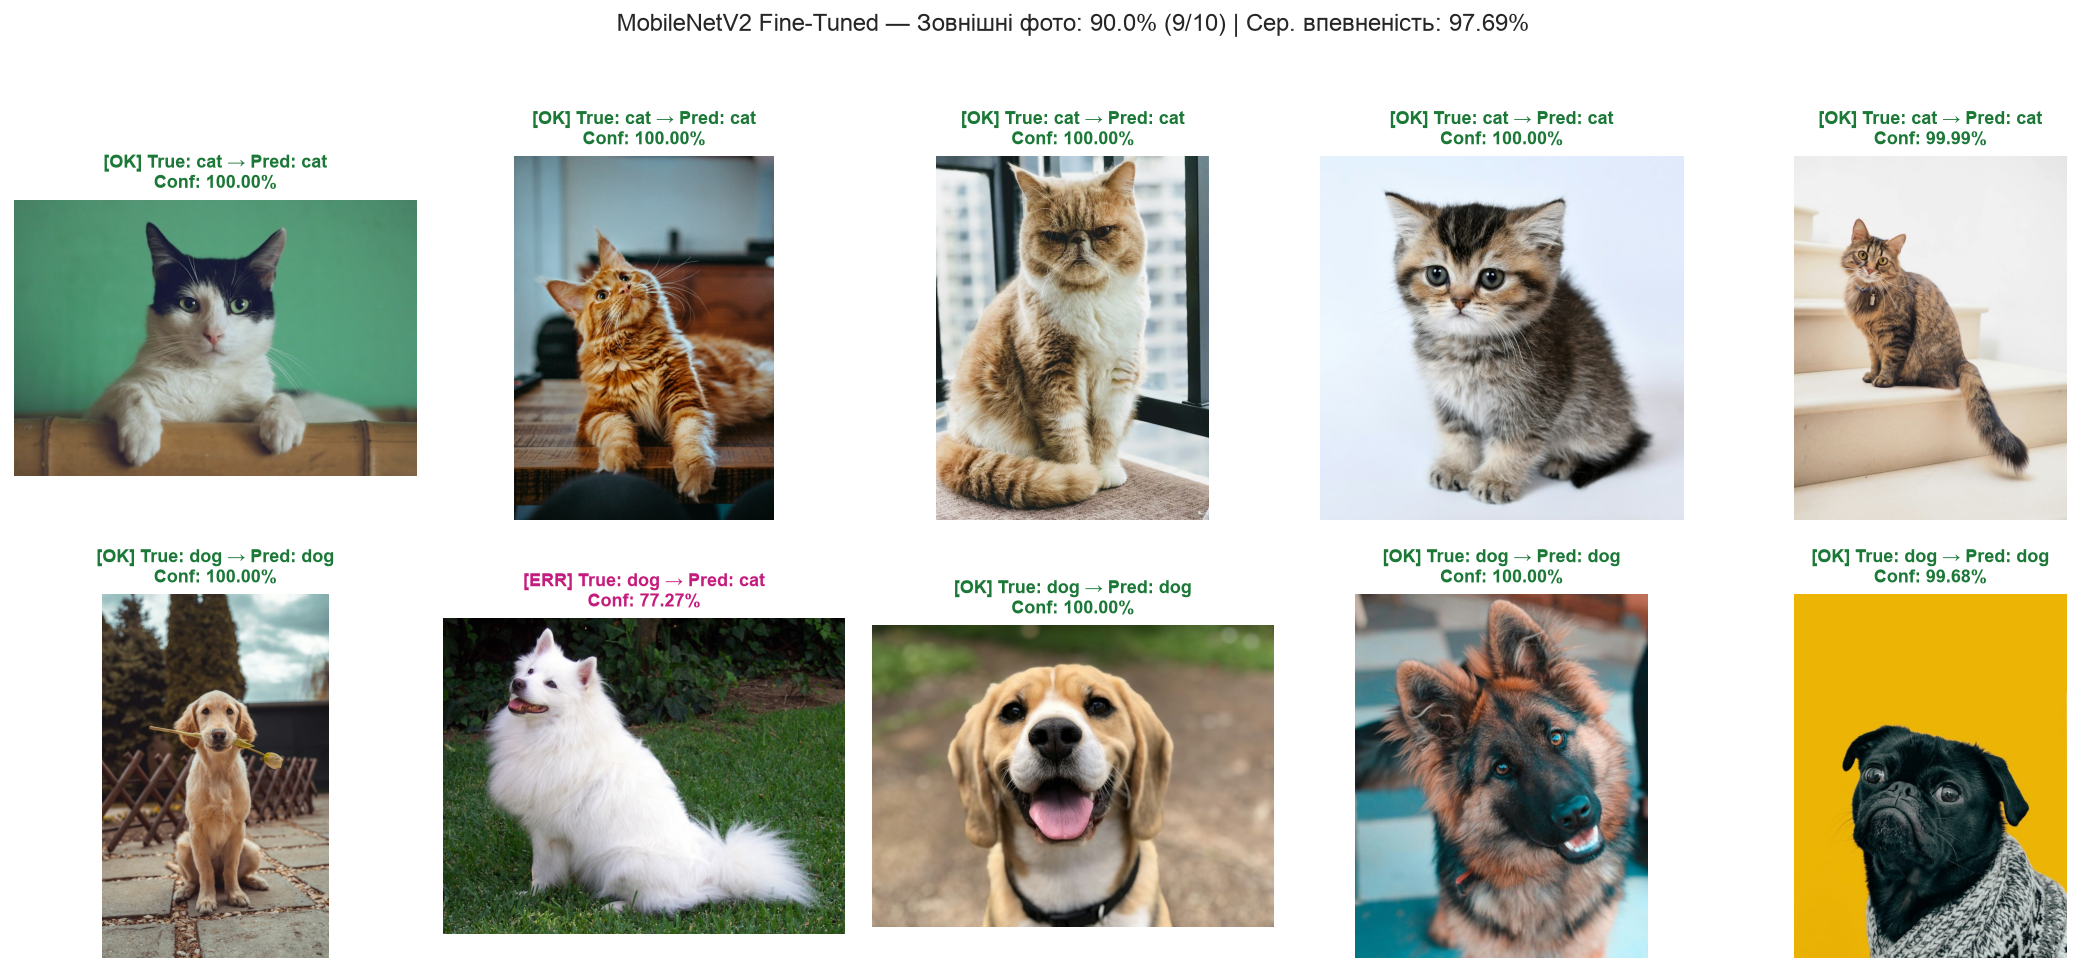

In [4]:
safe_lr_df = df_lr[df_lr["Learning Rate"] <= 1e-5]
best_row = safe_lr_df.sort_values("Best Val Loss").iloc[0]
best_opt = str(best_row["Optimizer"]).lower()
best_lr = float(best_row["Learning Rate"])
print(f"Оптимальний режим донавчання MobileNetV2 за мінімумом Val Loss: optimizer={best_opt}, lr={best_lr:.0e}, blocks=2")

full_prefix = prepare_prefix_cache(
    "mobilenet_v2",
    unfreeze_blocks=2,
    train_samples=None,
    val_samples=None,
)

champ_suffix, champ_rec = run_finetuning_experiment(
    model_key="mobilenet_v2",
    bottleneck_features=bottleneck_data,
    prefix_cache=full_prefix,
    unfreeze_blocks=2,
    dense_units=256,
    dropout_rate=0.5,
    optimizer_name=best_opt,
    learning_rate=best_lr,
    batch_size=50,
    warmup_epochs=20,
    finetune_epochs=8,
    warmup_on_full_train=True,
    experiment_name="mobilenet_v2_champion_finetuned",
    keep_model_in_memory=True,
)

plot_two_stage_curves(
    champ_rec,
    title_prefix="MobileNetV2 Champion (Stage 1 Full Warm-up + Stage 2 Fine-Tuning)",
    save_name="04_mobilenet_v2_champion_curves.png",
)

final_summary = finalize_and_save_finetuned_model(
    model_key="mobilenet_v2",
    trained_suffix_model=champ_suffix,
    experiment_record=champ_rec,
    prefix_cache=full_prefix,
)

plot_confusion_matrix(
    final_summary["test_metrics"]["confusion_matrix"],
    model_title="MobileNetV2 Fine-Tuned (Test Split, 2502 фото)",
    save_name="04_mobilenet_v2_confusion_matrix.png",
)

df_ext = predict_external_images(MODELS_DIR / final_summary["save_filename"])
display(df_ext)
plot_external_predictions_grid(
    df_ext,
    model_title="MobileNetV2 Fine-Tuned",
    save_name="04_mobilenet_v2_external_test.png",
)
